# Módulo 2 — Teoría y demostraciones

Notebook de apoyo para la teoría del **Día 3** (ver [`README.md`](../README.md)).

> **Sobre los datos de este módulo.** Los **📘 ejemplos resueltos** usan
> archivos **sintéticos** que genera `synth_data.py`, con las mismas
> convenciones que un ERA5 o un GFS (CF, latitud descendente, nombres de
> variable). Así sabemos qué contienen y dan el mismo resultado en todas las
> computadoras. Los **✍️ tu turno** usan un ERA5 descargado de Copernicus:
> el Perú el 13 de diciembre de 2024
> (`data/era_muestra/era5_peru_20241213.nc`), bajado con `cdsapi` como en
> el Módulo 3.

## Sección 1 — NetCDF: dimensiones, variables y atributos

Construimos un `Dataset` con la misma convención que ERA5 (ver
`synth_data.py`) y lo guardamos como archivo `.nc`, para inspeccionarlo
como si lo hubiéramos descargado.

In [1]:
from synth_data import era5_like_dataset

ds = era5_like_dataset(periods=48, seed=1)
ds.to_netcdf("demo_era5_like.nc")
print("Archivo escrito: demo_era5_like.nc")

Archivo escrito: demo_era5_like.nc


In [2]:
import xarray as xr

ds_leido = xr.open_dataset("demo_era5_like.nc")
ds_leido

<xarray.Dataset> Size: 203kB
Dimensions:    (time: 48, latitude: 31, longitude: 17)
Coordinates:
  * time       (time) datetime64[ns] 384B 2026-01-15 ... 2026-01-16T23:00:00
  * latitude   (latitude) float64 248B 10.0 9.0 8.0 7.0 ... -18.0 -19.0 -20.0
  * longitude  (longitude) float64 136B -82.0 -81.0 -80.0 ... -68.0 -67.0 -66.0
Data variables:
    t2m        (time, latitude, longitude) float32 101kB ...
    msl        (time, latitude, longitude) float32 101kB ...
Attributes:
    Conventions:  CF-1.7
    institution:  Datos sinteticos (curso Python-WRF) - NO son ERA5 real
    history:      Generado localmente sin conexion a Copernicus CDS

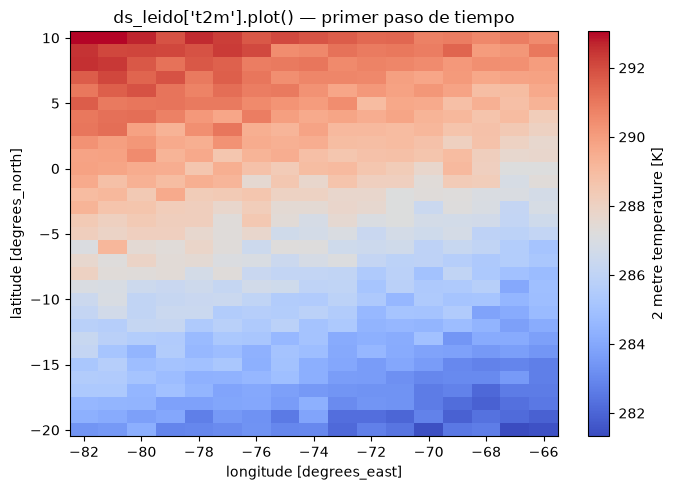

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
ds_leido["t2m"].isel(time=0).plot(ax=ax, cmap="coolwarm")
ax.set_title("ds_leido['t2m'].plot() — primer paso de tiempo")
fig.tight_layout()
plt.show()

In [4]:
print("Dimensiones:", dict(ds_leido.sizes))
print()
print("Variables de datos:", list(ds_leido.data_vars))
print()
print("Coordenadas:", list(ds_leido.coords))
print()
print("Atributos globales:")
for k, v in ds_leido.attrs.items():
    print(f"  {k}: {v}")

Dimensiones: {'time': 48, 'latitude': 31, 'longitude': 17}

Variables de datos: ['t2m', 'msl']

Coordenadas: ['time', 'latitude', 'longitude']

Atributos globales:
  Conventions: CF-1.7
  institution: Datos sinteticos (curso Python-WRF) - NO son ERA5 real
  history: Generado localmente sin conexion a Copernicus CDS


In [5]:
print("Atributos de la variable t2m:")
for k, v in ds_leido["t2m"].attrs.items():
    print(f"  {k}: {v}")

print()
print("¿La latitud es ascendente o descendente?")
lat = ds_leido["latitude"].values
print("  primeros valores:", lat[:3], "-> descendente" if lat[0] > lat[-1] else "-> ascendente")

Atributos de la variable t2m:
  units: K
  long_name: 2 metre temperature
  standard_name: air_temperature

¿La latitud es ascendente o descendente?
  primeros valores: [10.  9.  8.] -> descendente


## Sección 2 — Apertura perezosa (*lazy loading*)

Al abrir el archivo, Xarray lee solo la descripción (dimensiones, nombres,
atributos) y **todavía no trae los valores a memoria**. Se nota al
imprimir la variable: en vez de números, muestra cuántos valores hay.

In [6]:
import numpy as np

# Antes de cargar: Xarray solo sabe cuántos valores hay, no cuáles son
print("Antes de .load():")
print(str(ds_leido["t2m"]).splitlines()[1])

# .load() lee del disco todos los valores del Dataset y los deja en memoria
ds_leido.load()

print()
print("Después de .load():")
print(str(ds_leido["t2m"]).splitlines()[1])

Antes de .load():
[25296 values with dtype=float32]

Después de .load():
array([[[293.0169 , 293.0573 , 292.71085, ..., 290.58585, 290.86823,


En archivos de cientos de MB o más (como los `wrfout` del Módulo 4), esto
permite abrir el archivo e inspeccionar su estructura sin esperar a que se
lea todo.

## Sección 3 — GRIB2: un archivo generado con `eccodes`

En vez de descargar un GFS, armamos un mensaje GRIB2 con la librería
`eccodes` (la que usa `cfgrib` por debajo), a partir de las plantillas
(*samples*) que vienen con la instalación. No hace falta internet, y el
resultado es un archivo `.grib2` válido.

In [7]:
import eccodes

def escribir_grib2_sintetico(ruta, ni=8, nj=6, lat_first=10.0, lat_last=-5.0,
                              lon_first=-80.0, lon_last=-65.0, seed=0,
                              short_name="2t", fecha=20260315, hora=0):
    gid = eccodes.codes_grib_new_from_samples("regular_ll_sfc_grib2")
    eccodes.codes_set(gid, "Ni", ni)
    eccodes.codes_set(gid, "Nj", nj)
    eccodes.codes_set(gid, "latitudeOfFirstGridPointInDegrees", lat_first)
    eccodes.codes_set(gid, "longitudeOfFirstGridPointInDegrees", lon_first % 360)
    eccodes.codes_set(gid, "latitudeOfLastGridPointInDegrees", lat_last)
    eccodes.codes_set(gid, "longitudeOfLastGridPointInDegrees", lon_last % 360)
    eccodes.codes_set(gid, "iDirectionIncrementInDegrees", (lon_last - lon_first) / (ni - 1))
    eccodes.codes_set(gid, "jDirectionIncrementInDegrees", abs((lat_last - lat_first) / (nj - 1)))

    rng = np.random.default_rng(seed)
    valores = 293 + rng.normal(0, 2, ni * nj)
    eccodes.codes_set(gid, "shortName", short_name)
    eccodes.codes_set_values(gid, valores)
    eccodes.codes_set(gid, "dataDate", fecha)
    eccodes.codes_set(gid, "dataTime", hora)

    with open(ruta, "wb") as f:
        eccodes.codes_write(gid, f)
    eccodes.codes_release(gid)

escribir_grib2_sintetico("demo_gfs_like.grib2")
print("Archivo GRIB2 escrito: demo_gfs_like.grib2")

Archivo GRIB2 escrito: demo_gfs_like.grib2


In [8]:
ds_grib = xr.open_dataset("demo_gfs_like.grib2", engine="cfgrib")
ds_grib

<xarray.Dataset> Size: 336B
Dimensions:            (latitude: 6, longitude: 8)
Coordinates:
  * latitude           (latitude) float64 48B 10.0 7.0 4.0 1.0 -2.0 -5.0
  * longitude          (longitude) float64 64B 280.0 282.1 284.3 ... 292.9 295.0
    time               datetime64[ns] 8B ...
    step               timedelta64[ns] 8B ...
    heightAboveGround  float64 8B ...
    valid_time         datetime64[ns] 8B ...
Data variables:
    t2m                (latitude, longitude) float32 192B ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-24T03:26 GRIB to CDM+CF via cfgrib-0.9.1...

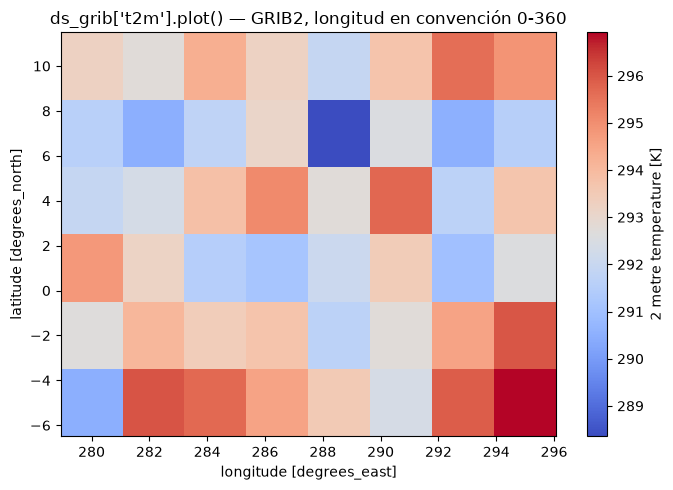

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ds_grib["t2m"].plot(ax=ax, cmap="coolwarm")
ax.set_title("ds_grib['t2m'].plot() — GRIB2, longitud en convención 0-360")
fig.tight_layout()
plt.show()

**Dos cosas para notar** (comparando con el NetCDF de la Sección 1):
1. La temperatura se llama `t2m` aquí también, pero en otras fuentes GRIB
   puede aparecer como `2t` o con otro nombre corto. El nombre de una
   variable cambia de una fuente a otra.
2. La longitud quedó en 0°–360° (`280°`–`295°`), aunque pedimos −180°/180°
   (`-80°`–`-65°`). Es común en productos GRIB, y hay que convertirla antes
   de cruzarla con un dataset en −180°/180°, como el NetCDF de la Sección 1.

In [10]:
print("Longitud en el GRIB2 (convención 0-360):", ds_grib["longitude"].values)

# Conversión a convención -180/180
lon_convertida = ((ds_grib["longitude"].values + 180) % 360) - 180
print("Longitud convertida a -180/180:          ", lon_convertida)

Longitud en el GRIB2 (convención 0-360): [280.         282.14285714 284.28571429 286.42857143 288.57142857
 290.71428571 292.85714286 295.        ]
Longitud convertida a -180/180:           [-80.         -77.85714286 -75.71428571 -73.57142857 -71.42857143
 -69.28571429 -67.14285714 -65.        ]


## Sección 4 — Selección, recorte e interpolación

**4a. El problema de la latitud descendente en `.sel(slice(...))`**

In [11]:
# ds_leido tiene latitud DESCENDENTE (10 -> -20), igual que ERA5 real
print("Rango real de latitud:", float(ds_leido.latitude.max()), "a", float(ds_leido.latitude.min()))

# Intento "ingenuo": slice(sur, norte) asumiendo orden ascendente
recorte_vacio = ds_leido.sel(latitude=slice(-20, 10))
print("slice(-20, 10) en un dataset descendente -> tamaño lat:", recorte_vacio.sizes["latitude"], "(¡vacío!)")

# Forma correcta: slice(norte, sur) porque la coordenada es descendente
recorte_ok = ds_leido.sel(latitude=slice(5, -10))
print("slice(5, -10) (orden correcto para descendente) -> tamaño lat:", recorte_ok.sizes["latitude"])

Rango real de latitud: 10.0 a -20.0
slice(-20, 10) en un dataset descendente -> tamaño lat: 0 (¡vacío!)
slice(5, -10) (orden correcto para descendente) -> tamaño lat: 16


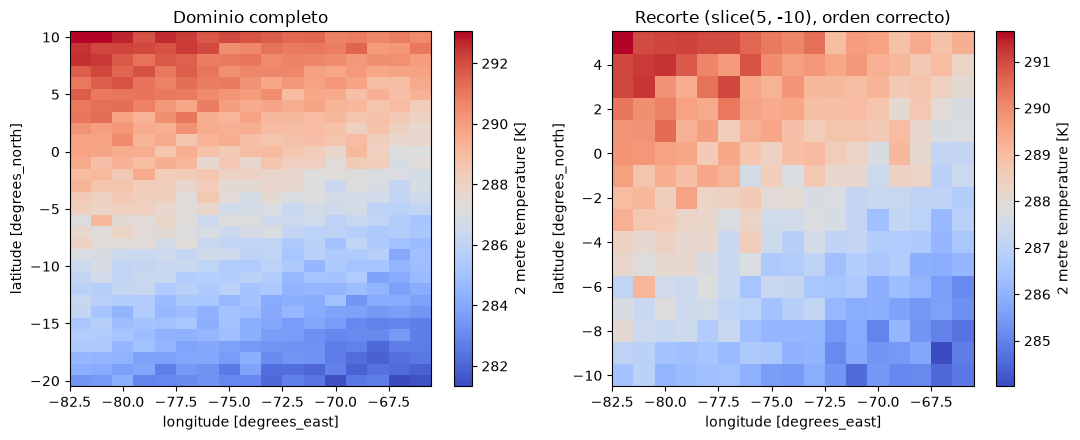

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ds_leido["t2m"].isel(time=0).plot(ax=axes[0], cmap="coolwarm")
axes[0].set_title("Dominio completo")
recorte_ok["t2m"].isel(time=0).plot(ax=axes[1], cmap="coolwarm")
axes[1].set_title("Recorte (slice(5, -10), orden correcto)")
fig.tight_layout()
plt.show()

**4b. Interpolación bilineal vs. vecino más cercano**

Si un punto (x, y) cae entre 4 nodos de la grilla (Q11, Q12, Q21, Q22:
abajo-izquierda, arriba-izquierda, abajo-derecha, arriba-derecha), la
interpolación bilineal calcula un promedio ponderado de los 4 valores.
Cada nodo pesa más cuanto más cerca está del punto, y los cuatro pesos
suman 1.

In [13]:
punto_lat, punto_lon = -8.5, -76.3  # no coincide con ningún nodo de la grilla

serie_nearest = ds_leido["t2m"].sel(latitude=punto_lat, longitude=punto_lon, method="nearest")
serie_interp = ds_leido["t2m"].interp(latitude=punto_lat, longitude=punto_lon, method="linear")

print("Nearest  (primeros 5 valores):", serie_nearest.values[:5].round(3))
print("Interp   (primeros 5 valores):", serie_interp.values[:5].round(3))

Nearest  (primeros 5 valores): [286.326 286.136 285.917 285.608 285.89 ]
Interp   (primeros 5 valores): [286.572 286.018 285.701 285.48  285.718]


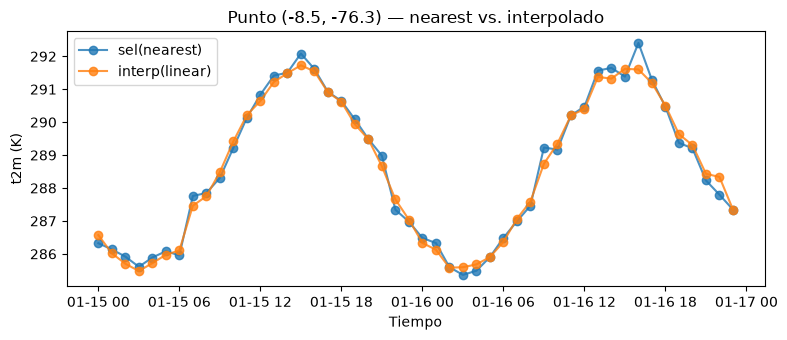

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(ds_leido["time"], serie_nearest.values, "o-", label="sel(nearest)", alpha=0.8)
ax.plot(ds_leido["time"], serie_interp.values, "o-", label="interp(linear)", alpha=0.8)
ax.set_xlabel("Tiempo")
ax.set_ylabel("t2m (K)")
ax.set_title(f"Punto ({punto_lat}, {punto_lon}) — nearest vs. interpolado")
ax.legend()
fig.tight_layout()
plt.show()

In [15]:
# Verificación manual de la fórmula bilineal para el PRIMER instante de tiempo
t2m_t0 = ds_leido["t2m"].isel(time=0)

lat_vals = ds_leido["latitude"].values
lon_vals = ds_leido["longitude"].values

# Nodos que rodean (punto_lat, punto_lon); latitud descendente => hay que
# buscar el nodo inmediatamente MAYOR y el inmediatamente MENOR
i_lat_sup = np.where(lat_vals >= punto_lat)[0][-1]   # el más cercano por arriba
i_lat_inf = i_lat_sup + 1                             # el más cercano por abajo
j_lon_izq = np.where(lon_vals <= punto_lon)[0][-1]
j_lon_der = j_lon_izq + 1

y1, y2 = lat_vals[i_lat_inf], lat_vals[i_lat_sup]
x1, x2 = lon_vals[j_lon_izq], lon_vals[j_lon_der]

Q11 = t2m_t0.values[i_lat_inf, j_lon_izq]
Q21 = t2m_t0.values[i_lat_inf, j_lon_der]
Q12 = t2m_t0.values[i_lat_sup, j_lon_izq]
Q22 = t2m_t0.values[i_lat_sup, j_lon_der]

x, y = punto_lon, punto_lat
manual = (
    Q11 * (x2 - x) * (y2 - y) +
    Q21 * (x - x1) * (y2 - y) +
    Q12 * (x2 - x) * (y - y1) +
    Q22 * (x - x1) * (y - y1)
) / ((x2 - x1) * (y2 - y1))

print(f"Interpolación bilineal manual : {manual:.4f} K")
print(f"Interpolación con .interp()   : {float(serie_interp.isel(time=0)):.4f} K")
print(f"¿Coinciden? -> {np.isclose(manual, float(serie_interp.isel(time=0)), atol=1e-3)}")

Interpolación bilineal manual : 286.5715 K
Interpolación con .interp()   : 286.5715 K
¿Coinciden? -> True


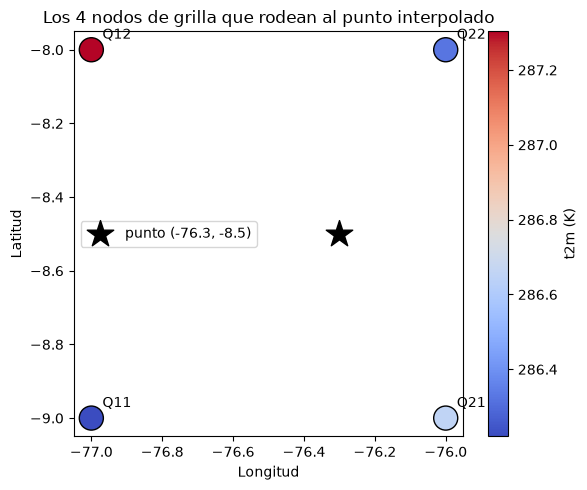

In [16]:
# Geometria del problema: los 4 nodos que rodean al punto, y donde cae el punto
fig, ax = plt.subplots(figsize=(6, 5))
nodos_x = [x1, x2, x1, x2]
nodos_y = [y1, y1, y2, y2]
nodos_val = [Q11, Q21, Q12, Q22]
sc = ax.scatter(nodos_x, nodos_y, c=nodos_val, s=300, cmap="coolwarm", edgecolor="k", zorder=2)
for xi, yi, label in zip(nodos_x, nodos_y, ["Q11", "Q21", "Q12", "Q22"]):
    ax.annotate(label, (xi, yi), textcoords="offset points", xytext=(8, 8))
ax.scatter([x], [y], marker="*", s=400, color="black", zorder=3, label=f"punto ({x:.1f}, {y:.1f})")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Los 4 nodos de grilla que rodean al punto interpolado")
plt.colorbar(sc, ax=ax, label="t2m (K)")
ax.legend()
fig.tight_layout()
plt.show()

---
Continuar con la práctica en
[`02_practica_inspeccion_netcdf_grib.ipynb`](02_practica_inspeccion_netcdf_grib.ipynb).